In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [6]:
df = pd.read_csv('/content/logistics_delivery_dataset.csv')

In [7]:
df.head()

,Order_ID,Order_Date,Warehouse,Distance,Delivery_Time,Vehicle_Type,Fuel_Used,Delivery_Status
0,ORD1000,2025-01-01,Hyderabad_WH1,11.35,50.7,Mini_Van,0.81,Delayed
1,ORD1001,2025-01-01,Coimbatore_WH1,50.81,130.5,Truck_Small,6.35,On Time
2,ORD1002,2025-01-01,Bangalore_WH1,6.90,46.8,Bike,0.17,On Time
3,ORD1003,2025-01-01,Coimbatore_WH1,136.05,319.4,Truck_Large,27.21,On Time
4,ORD1004,2025-01-02,Coimbatore_WH1,33.61,77.2,Mini_Van,2.40,On Time


In [8]:
df.shape

(503, 8)

In [9]:
df.columns

Index(['Order_ID', 'Order_Date', 'Warehouse', 'Distance', 'Delivery_Time',
       'Vehicle_Type', 'Fuel_Used', 'Delivery_Status'],
      dtype='object')

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 503 entries, 0 to 502
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order_ID         503 non-null    object 
 1   Order_Date       503 non-null    object 
 2   Warehouse        503 non-null    object 
 3   Distance         498 non-null    float64
 4   Delivery_Time    503 non-null    float64
 5   Vehicle_Type     503 non-null    object 
 6   Fuel_Used        499 non-null    float64
 7   Delivery_Status  503 non-null    object 
dtypes: float64(3), object(5)
memory usage: 31.6+ KB


In [11]:
df.isnull().sum()

,0
Order_ID,0
Order_Date,0
Warehouse,0
Distance,5
Delivery_Time,0
Vehicle_Type,0
Fuel_Used,4
Delivery_Status,0


In [12]:
df.duplicated().sum()

np.int64(3)

In [13]:
df = df.drop_duplicates()

In [14]:
df.describe()

,Distance,Delivery_Time,Fuel_Used
count,495.000000,500.000000,496.000000
mean,31.191051,93.889800,4.259758
std,32.540548,77.047161,6.715097
min,1.090000,5.000000,0.030000
25%,9.240000,43.550000,0.280000
50%,18.410000,67.800000,1.455000
75%,39.060000,118.300000,5.150000
max,149.730000,493.700000,29.950000


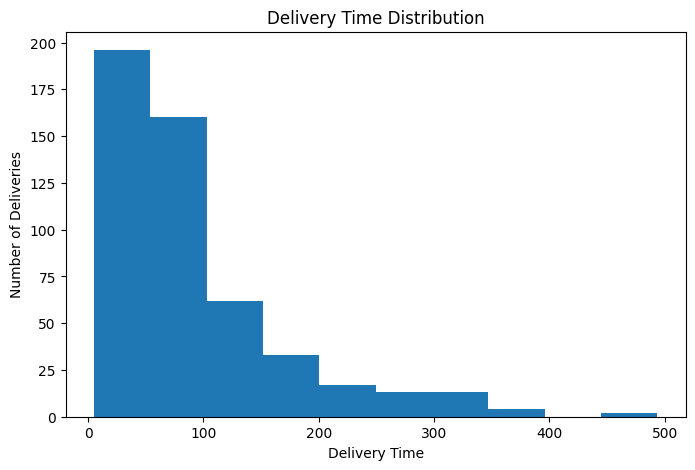

In [15]:
plt.figure(figsize=(8,5))
plt.hist(df['Delivery_Time'])
plt.xlabel('Delivery Time')
plt.ylabel('Number of Deliveries')
plt.title('Delivery Time Distribution')
plt.show()

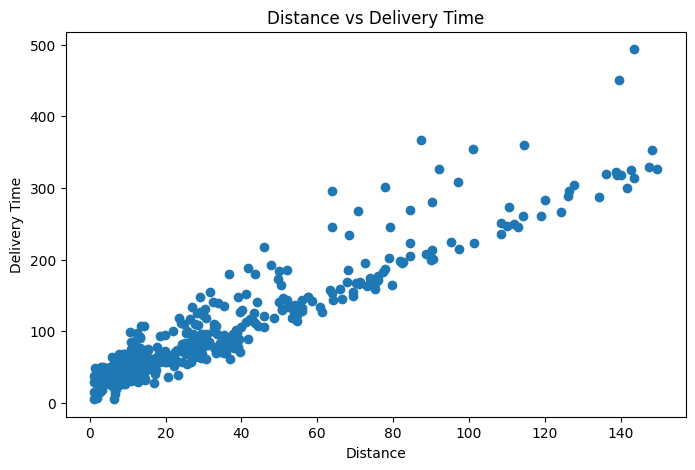

In [16]:
plt.figure(figsize=(8,5))
plt.scatter(df['Distance'], df['Delivery_Time'])
plt.xlabel('Distance')
plt.ylabel('Delivery Time')
plt.title('Distance vs Delivery Time')
plt.show()

In [17]:
df.groupby('Vehicle_Type')['Delivery_Time'].mean()

,Delivery_Time
Vehicle_Type,
Bike,44.510497
Mini_Van,68.793631
Truck_Large,224.563291
Truck_Small,124.667470


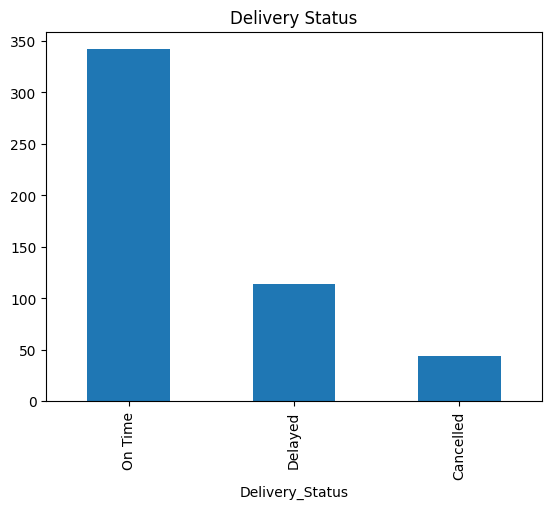

In [18]:
df['Delivery_Status'].value_counts().plot(kind='bar')
plt.title('Delivery Status')
plt.show()

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [20]:
from google.colab import files

uploaded = files.upload()

Saving logistics_delivery_dataset.csv to logistics_delivery_dataset (1).csv


In [21]:
filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

df.head()

,Order_ID,Order_Date,Warehouse,Distance,Delivery_Time,Vehicle_Type,Fuel_Used,Delivery_Status
0,ORD1000,2025-01-01,Hyderabad_WH1,11.35,50.7,Mini_Van,0.81,Delayed
1,ORD1001,2025-01-01,Coimbatore_WH1,50.81,130.5,Truck_Small,6.35,On Time
2,ORD1002,2025-01-01,Bangalore_WH1,6.90,46.8,Bike,0.17,On Time
3,ORD1003,2025-01-01,Coimbatore_WH1,136.05,319.4,Truck_Large,27.21,On Time
4,ORD1004,2025-01-02,Coimbatore_WH1,33.61,77.2,Mini_Van,2.40,On Time


In [22]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

Dataset Shape: (503, 8)

Column Names:
Index(['Order_ID', 'Order_Date', 'Warehouse', 'Distance', 'Delivery_Time',
       'Vehicle_Type', 'Fuel_Used', 'Delivery_Status'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 503 entries, 0 to 502
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order_ID         503 non-null    object 
 1   Order_Date       503 non-null    object 
 2   Warehouse        503 non-null    object 
 3   Distance         498 non-null    float64
 4   Delivery_Time    503 non-null    float64
 5   Vehicle_Type     503 non-null    object 
 6   Fuel_Used        499 non-null    float64
 7   Delivery_Status  503 non-null    object 
dtypes: float64(3), object(5)
memory usage: 31.6+ KB


In [23]:
print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())


Missing Values:
Order_ID           0
Order_Date         0
Warehouse          0
Distance           5
Delivery_Time      0
Vehicle_Type       0
Fuel_Used          4
Delivery_Status    0
dtype: int64

Duplicate Rows:
3


In [24]:
# Remove duplicate rows
df = df.drop_duplicates()

# Fill missing Distance with median
df['Distance'] = df['Distance'].fillna(df['Distance'].median())

# Fill missing Fuel_Used with median
df['Fuel_Used'] = df['Fuel_Used'].fillna(df['Fuel_Used'].median())

print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nDuplicate rows after cleaning:")
print(df.duplicated().sum())

print("\nNew dataset shape:")
print(df.shape)

Missing values after cleaning:
Order_ID           0
Order_Date         0
Warehouse          0
Distance           0
Delivery_Time      0
Vehicle_Type       0
Fuel_Used          0
Delivery_Status    0
dtype: int64

Duplicate rows after cleaning:
0

New dataset shape:
(500, 8)


In [25]:
df.describe()

,Distance,Delivery_Time,Fuel_Used
count,500.000000,500.000000,500.000000
mean,31.063240,93.889800,4.237320
std,32.402124,77.047161,6.692804
min,1.090000,5.000000,0.030000
25%,9.260000,43.550000,0.280000
50%,18.410000,67.800000,1.455000
75%,38.932500,118.300000,5.060000
max,149.730000,493.700000,29.950000


In [26]:
print("Average Distance:", df['Distance'].mean())
print("Average Delivery Time:", df['Delivery_Time'].mean())
print("Average Fuel Used:", df['Fuel_Used'].mean())

Average Distance: 31.063239999999997
Average Delivery Time: 93.88980000000001
Average Fuel Used: 4.2373199999999995


In [27]:
df['Order_Date'] = pd.to_datetime(df['Order_Date'])

print(df['Order_Date'].min())
print(df['Order_Date'].max())

2025-01-01 00:00:00
2025-05-05 00:00:00


In [28]:
df.head()

,Order_ID,Order_Date,Warehouse,Distance,Delivery_Time,Vehicle_Type,Fuel_Used,Delivery_Status
0,ORD1000,2025-01-01,Hyderabad_WH1,11.35,50.7,Mini_Van,0.81,Delayed
1,ORD1001,2025-01-01,Coimbatore_WH1,50.81,130.5,Truck_Small,6.35,On Time
2,ORD1002,2025-01-01,Bangalore_WH1,6.90,46.8,Bike,0.17,On Time
3,ORD1003,2025-01-01,Coimbatore_WH1,136.05,319.4,Truck_Large,27.21,On Time
4,ORD1004,2025-01-02,Coimbatore_WH1,33.61,77.2,Mini_Van,2.40,On Time


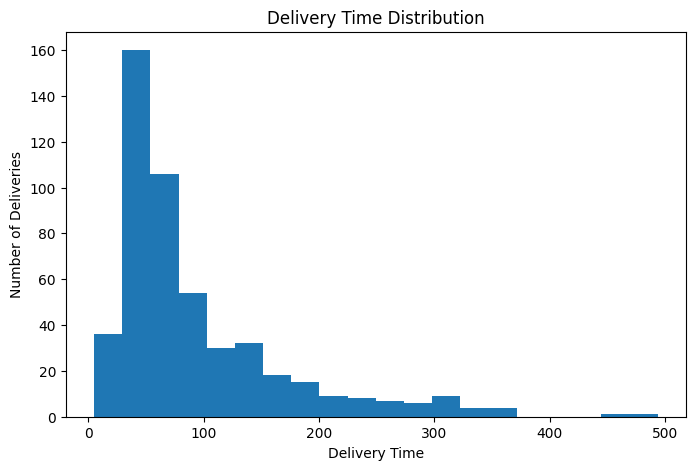

In [29]:
plt.figure(figsize=(8,5))

plt.hist(df['Delivery_Time'], bins=20)

plt.xlabel('Delivery Time')
plt.ylabel('Number of Deliveries')
plt.title('Delivery Time Distribution')

plt.show()

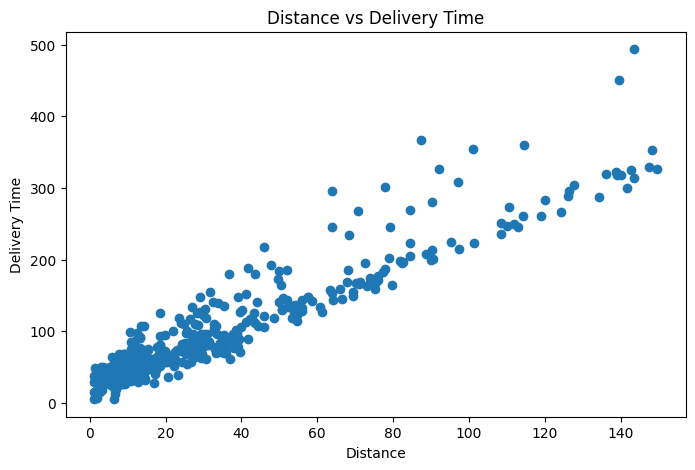

In [30]:
plt.figure(figsize=(8,5))

plt.scatter(df['Distance'], df['Delivery_Time'])

plt.xlabel('Distance')
plt.ylabel('Delivery Time')
plt.title('Distance vs Delivery Time')

plt.show()

In [31]:
vehicle_time = df.groupby('Vehicle_Type')['Delivery_Time'].mean()

print(vehicle_time)

Vehicle_Type
Bike            44.510497
Mini_Van        68.793631
Truck_Large    224.563291
Truck_Small    124.667470
Name: Delivery_Time, dtype: float64


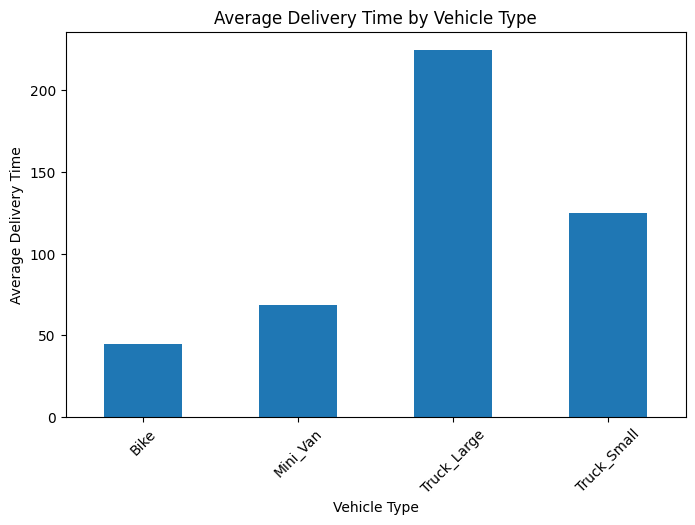

In [32]:
plt.figure(figsize=(8,5))

vehicle_time.plot(kind='bar')

plt.xlabel('Vehicle Type')
plt.ylabel('Average Delivery Time')
plt.title('Average Delivery Time by Vehicle Type')

plt.xticks(rotation=45)

plt.show()

In [33]:
print(df['Delivery_Status'].value_counts())

Delivery_Status
On Time      342
Delayed      114
Cancelled     44
Name: count, dtype: int64


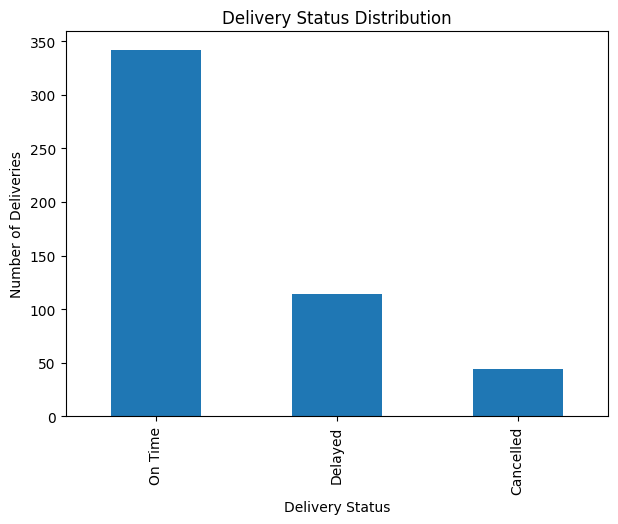

In [34]:
plt.figure(figsize=(7,5))

df['Delivery_Status'].value_counts().plot(kind='bar')

plt.xlabel('Delivery Status')
plt.ylabel('Number of Deliveries')
plt.title('Delivery Status Distribution')

plt.show()

In [35]:
print(df['Delivery_Status'].value_counts())

Delivery_Status
On Time      342
Delayed      114
Cancelled     44
Name: count, dtype: int64


In [36]:
on_time_rate = (
    (df['Delivery_Status'] == 'On Time').sum()
    / len(df)
) * 100

print("On-Time Delivery Rate:", round(on_time_rate, 2), "%")

On-Time Delivery Rate: 68.4 %


In [37]:
average_delivery_time = df['Delivery_Time'].mean()

print(
    "Average Delivery Time:",
    round(average_delivery_time, 2)
)

Average Delivery Time: 93.89


In [38]:
average_distance = df['Distance'].mean()

print("Average Distance:", round(average_distance, 2))

Average Distance: 31.06


In [39]:
average_fuel = df['Fuel_Used'].mean()

print("Average Fuel Used:", round(average_fuel, 2))

Average Fuel Used: 4.24


In [40]:
df['Fuel_Efficiency'] = df['Distance'] / df['Fuel_Used']

In [41]:
print(
    "Average Fuel Efficiency:",
    round(df['Fuel_Efficiency'].mean(), 2)
)

Average Fuel Efficiency: 20.89


In [42]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

X = df[['Distance', 'Fuel_Used']]
y = df['Delivery_Time']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

model = RandomForestRegressor(
    random_state=42
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Predictions completed!")

Predictions completed!


In [43]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, predictions)

rmse = np.sqrt(
    mean_squared_error(y_test, predictions)
)

r2 = r2_score(y_test, predictions)

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R² Score:", round(r2, 2))

MAE: 20.0
RMSE: 30.89
R² Score: 0.82


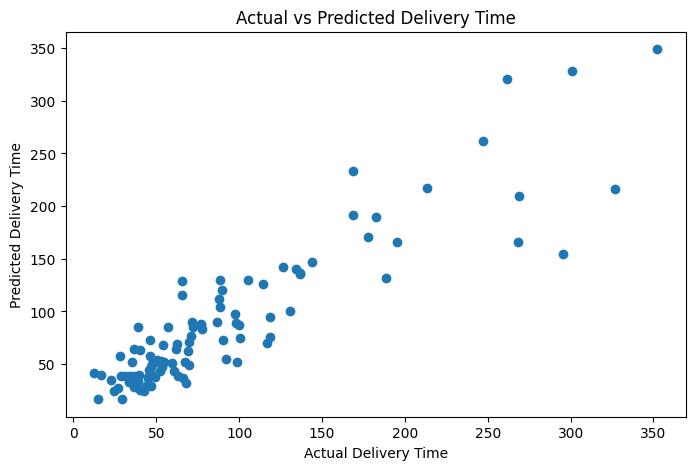

In [44]:
plt.figure(figsize=(8,5))

plt.scatter(y_test, predictions)

plt.xlabel('Actual Delivery Time')
plt.ylabel('Predicted Delivery Time')
plt.title('Actual vs Predicted Delivery Time')

plt.show()

In [45]:
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
)

print(importance)

Distance     0.574469
Fuel_Used    0.425531
dtype: float64


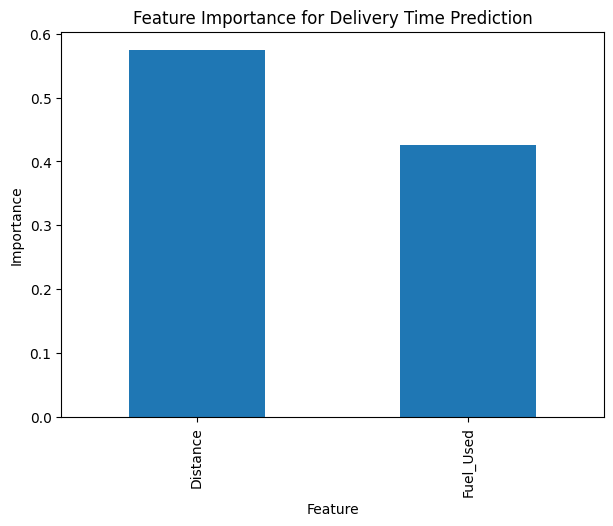

In [46]:
plt.figure(figsize=(7,5))

importance.plot(kind='bar')

plt.xlabel('Feature')
plt.ylabel('Importance')
plt.title('Feature Importance for Delivery Time Prediction')

plt.show()

In [47]:
from sklearn.cluster import KMeans

X_cluster = df[['Distance', 'Delivery_Time']]

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X_cluster)

print(df[['Order_ID', 'Distance', 'Delivery_Time', 'Cluster']].head())

  Order_ID  Distance  Delivery_Time  Cluster
0  ORD1000     11.35           50.7        0
1  ORD1001     50.81          130.5        2
2  ORD1002      6.90           46.8        0
3  ORD1003    136.05          319.4        1
4  ORD1004     33.61           77.2        0


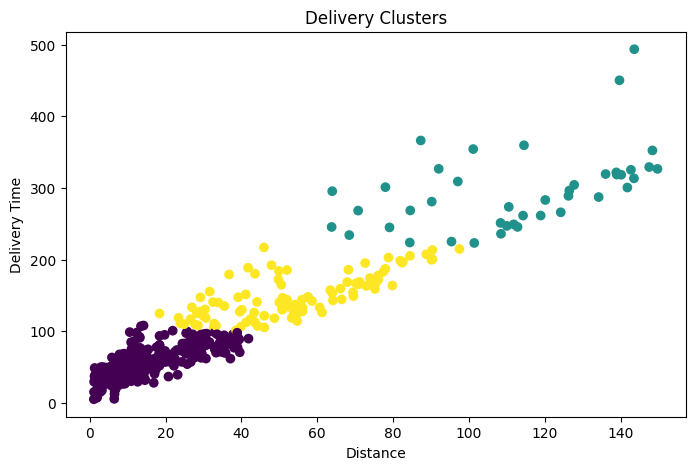

In [48]:
plt.figure(figsize=(8,5))

plt.scatter(
    df['Distance'],
    df['Delivery_Time'],
    c=df['Cluster']
)

plt.xlabel('Distance')
plt.ylabel('Delivery Time')
plt.title('Delivery Clusters')

plt.show()

In [49]:
cluster_summary = df.groupby('Cluster')[
    ['Distance', 'Delivery_Time', 'Fuel_Used']
].mean()

print(cluster_summary)

           Distance  Delivery_Time  Fuel_Used
Cluster                                      
0         15.046246      54.581513   1.064762
1        112.798571     296.392857  22.056190
2         53.688812     148.621782   8.041386


In [50]:
df.to_csv(
    'logistics_delivery_cleaned.csv',
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
